# Proyecto Integrador de Minería de Datos: Segmentación de Precios de APIs de LLMs con K-Means

Este cuaderno realiza un análisis completo paso a paso sobre el dataset `price_snapshots.csv` (precios históricos de APIs de Modelos de Lenguaje Grande / LLMs) aplicando el algoritmo de aprendizaje no supervisado **K-Means**.

### Estructura del análisis
1. **Exploración inicial (EDA)** y generación de 3 gráficas exploratorias guardadas en `img/`.
2. **Limpieza y preparación de datos** (selección de variables, nulos, duplicados, tratamiento de outliers por IQR y escalamiento con `StandardScaler`).
3. **Implementación de K-Means** evaluando $K \in \{2, 3, 4, 5, 6\}$ mediante Método del Codo (Inercia) y Silhouette Score, y entrenamiento del modelo final.
4. **Comparación de 2 configuraciones**: Modelo final con datos escalados vs. modelo con datos sin escalar.
5. **Interpretación de clústeres y exportación** a `data/dataset_procesado.csv` para el dashboard interactivo en Streamlit.


## 1. Exploración Inicial de Datos (EDA)


In [1]:
# Importación de librerías necesarias para análisis, visualización y modelado K-Means
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración visual general y supresión de advertencias menores
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

# Crear carpeta img/ para guardar las gráficas exploratorias en formato PNG
IMG_DIR = os.path.join("..", "img")
DATA_DIR = os.path.join("..", "data")
os.makedirs(IMG_DIR, exist_ok=True)

print("Librerías cargadas correctamente y carpetas verificadas.")


Librerías cargadas correctamente y carpetas verificadas.


In [2]:
# Carga del dataset original price_snapshots.csv con pandas
ruta_csv = os.path.join(DATA_DIR, "price_snapshots.csv")
df = pd.read_csv(ruta_csv)

# Mostrar los primeros 10 registros del dataset
print("Primeros 10 registros del dataset:")
display(df.head(10))


Primeros 10 registros del dataset:


,snapshot_date,provider,model_id,model_display_name,model_family,is_alias,price_tier,modality,unit,input_usd_per_1m,...,cache_write_usd_per_1m,cache_write_5m_usd_per_1m,cache_write_1h_usd_per_1m,cache_storage_usd_per_1m_per_hour,context_threshold_tokens,price_basis,is_promotional,notes,source_url,retrieved_at_iso
0,2026-09-20,OpenAI,gpt-6-astra,gpt-6-astra,chat,False,standard,text,usd_per_1m_tokens,10.0,...,12.50,NaN,NaN,NaN,NaN,listed,False,short_context,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
1,2026-09-20,OpenAI,gpt-6-astra,gpt-6-astra,chat,False,standard_long_context,text,usd_per_1m_tokens,20.0,...,25.00,NaN,NaN,NaN,NaN,listed,False,long_context tier as listed on pricing page,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
2,2026-09-20,OpenAI,gpt-5.6-sol,gpt-5.6-sol,chat,False,standard,text,usd_per_1m_tokens,4.0,...,5.00,NaN,NaN,NaN,NaN,listed,False,short_context,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
3,2026-09-20,OpenAI,gpt-5.6-sol,gpt-5.6-sol,chat,False,standard_long_context,text,usd_per_1m_tokens,8.0,...,10.00,NaN,NaN,NaN,NaN,listed,False,long_context tier as listed on pricing page,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
4,2026-09-20,OpenAI,gpt-5.6-terra,gpt-5.6-terra,chat,False,standard,text,usd_per_1m_tokens,2.0,...,2.50,NaN,NaN,NaN,NaN,listed,False,short_context,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
5,2026-09-20,OpenAI,gpt-5.6-terra,gpt-5.6-terra,chat,False,standard_long_context,text,usd_per_1m_tokens,4.0,...,5.00,NaN,NaN,NaN,NaN,listed,False,long_context tier as listed on pricing page,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
6,2026-09-20,OpenAI,gpt-5.6-luna,gpt-5.6-luna,chat,False,standard,text,usd_per_1m_tokens,0.2,...,0.25,NaN,NaN,NaN,NaN,listed,False,short_context,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
7,2026-09-20,OpenAI,gpt-5.6-luna,gpt-5.6-luna,chat,False,standard_long_context,text,usd_per_1m_tokens,0.4,...,0.50,NaN,NaN,NaN,NaN,listed,False,long_context tier as listed on pricing page,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
8,2026-09-20,OpenAI,gpt-5.5,gpt-5.5 (<272K context),chat,False,standard,text,usd_per_1m_tokens,5.0,...,NaN,NaN,NaN,NaN,272000.0,listed,False,Listed threshold <272000 tokens for standard t...,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00
9,2026-09-20,OpenAI,gpt-5.5,gpt-5.5 (<272K context),chat,False,standard_long_context,text,usd_per_1m_tokens,10.0,...,NaN,NaN,NaN,NaN,272000.0,listed,False,long_context tier as listed on pricing page,https://developers.openai.com/api/docs/pricing,2026-09-20T10:12:17+09:00


In [3]:
# Inspección de dimensiones, nombres de columnas y tipos de datos
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas\n")

print("Columnas disponibles:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col} ({df[col].dtype})")

print("\nInformación general (df.info()):")
df.info()


Dimensiones del dataset: 2970 filas x 22 columnas

Columnas disponibles:
   1. snapshot_date (str)
   2. provider (str)
   3. model_id (str)
   4. model_display_name (str)
   5. model_family (str)
   6. is_alias (bool)
   7. price_tier (str)
   8. modality (str)
   9. unit (str)
  10. input_usd_per_1m (float64)
  11. output_usd_per_1m (float64)
  12. cached_input_usd_per_1m (float64)
  13. cache_write_usd_per_1m (float64)
  14. cache_write_5m_usd_per_1m (float64)
  15. cache_write_1h_usd_per_1m (float64)
  16. cache_storage_usd_per_1m_per_hour (float64)
  17. context_threshold_tokens (float64)
  18. price_basis (str)
  19. is_promotional (bool)
  20. notes (str)
  21. source_url (str)
  22. retrieved_at_iso (str)

Información general (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 2970 entries, 0 to 2969
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   snapshot_date 

In [4]:
# Estadísticas descriptivas de variables numéricas, conteo de nulos y duplicados
print("Estadísticas descriptivas de las variables numéricas:")
display(df.describe().T)

print("\nConteo de valores nulos por columna:")
nulos = df.isnull().sum()
porcentaje_nulos = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({"Nulos": nulos, "Porcentaje (%)": porcentaje_nulos})
display(resumen_nulos[resumen_nulos["Nulos"] > 0])

duplicados_totales = df.duplicated().sum()
print(f"\nTotal de filas completamente duplicadas: {duplicados_totales}")


Estadísticas descriptivas de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
input_usd_per_1m,2970.0,4.387734,10.200358,0.0000,0.45,1.800,4.00,150.00
output_usd_per_1m,2902.0,20.611692,45.332647,0.0000,2.20,7.500,20.00,600.00
cached_input_usd_per_1m,2456.0,0.362434,0.592741,0.0025,0.05,0.200,0.40,7.50
cache_write_usd_per_1m,911.0,5.805708,7.431864,0.0625,1.25,3.125,6.25,50.00
cache_write_5m_usd_per_1m,365.0,5.388699,4.571207,0.1250,2.00,3.750,6.25,18.75
cache_write_1h_usd_per_1m,365.0,8.684384,7.288732,0.2000,4.00,6.000,10.00,30.00
cache_storage_usd_per_1m_per_hour,420.0,2.455714,2.341020,0.5000,1.00,1.000,4.50,8.10
context_threshold_tokens,530.0,224060.377358,45453.523656,100000.0000,200000.00,200000.000,272000.00,272000.00



Conteo de valores nulos por columna:


,Nulos,Porcentaje (%)
output_usd_per_1m,68,2.29
cached_input_usd_per_1m,514,17.31
cache_write_usd_per_1m,2059,69.33
cache_write_5m_usd_per_1m,2605,87.71
cache_write_1h_usd_per_1m,2605,87.71
cache_storage_usd_per_1m_per_hour,2550,85.86
context_threshold_tokens,2440,82.15
notes,288,9.70



Total de filas completamente duplicadas: 0


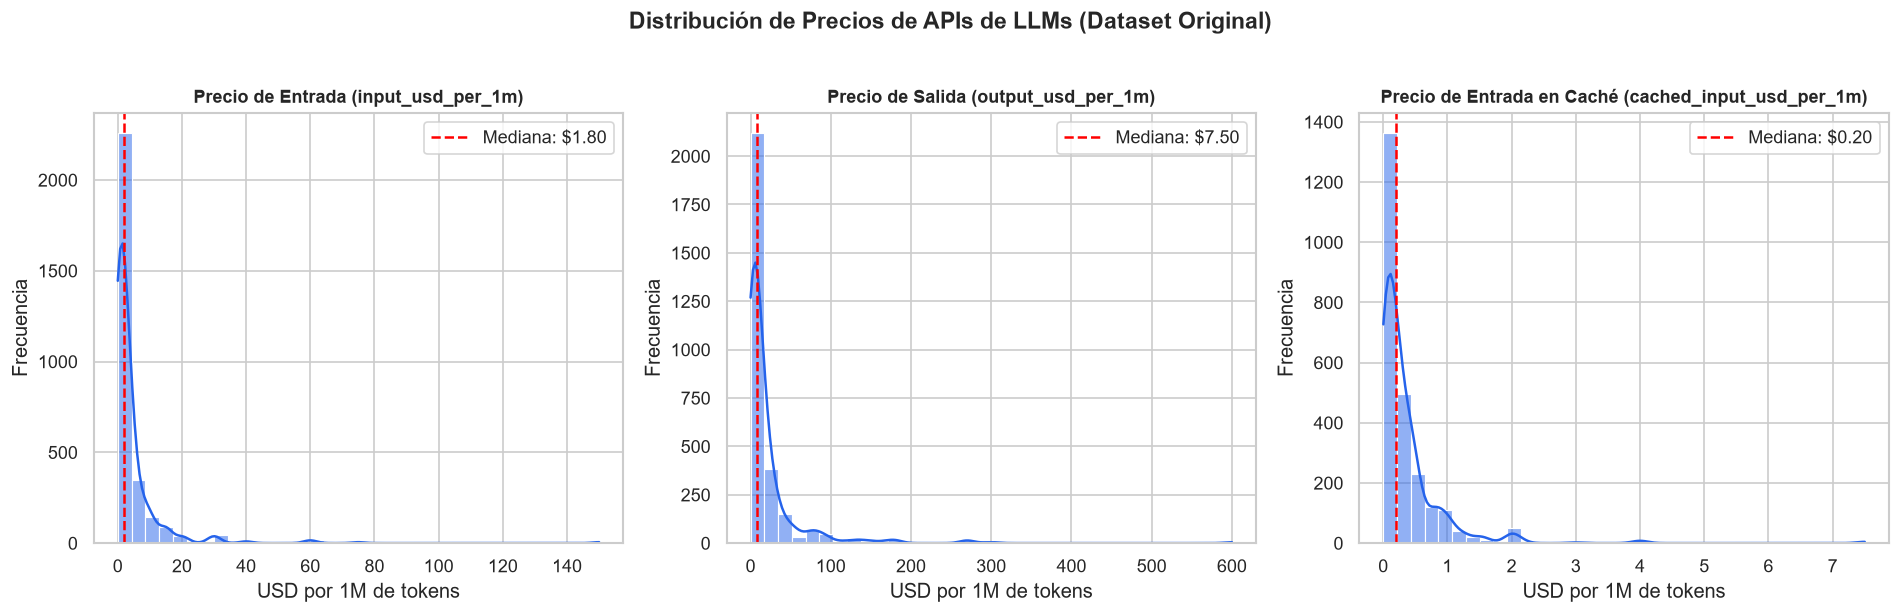

Gráfica guardada en: ..\img\01_distribucion_precios.png


In [5]:
# Gráfica Exploratoria 1: Distribución de las 3 variables principales de precio (histogramas con escala logarítmica)
cols_precio = ["input_usd_per_1m", "output_usd_per_1m", "cached_input_usd_per_1m"]
titulos_vars = [
    "Precio de Entrada (input_usd_per_1m)",
    "Precio de Salida (output_usd_per_1m)",
    "Precio de Entrada en Caché (cached_input_usd_per_1m)"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, titulo in zip(axes, cols_precio, titulos_vars):
    datos_validos = df[col].dropna()
    sns.histplot(datos_validos, bins=35, kde=True, ax=ax, color="#2563EB")
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel("USD por 1M de tokens")
    ax.set_ylabel("Frecuencia")
    ax.axvline(datos_validos.median(), color="red", linestyle="--", label=f"Mediana: ${datos_validos.median():.2f}")
    ax.legend()

plt.suptitle("Distribución de Precios de APIs de LLMs (Dataset Original)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_img1 = os.path.join(IMG_DIR, "01_distribucion_precios.png")
plt.savefig(ruta_img1, dpi=150, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada en: {ruta_img1}")


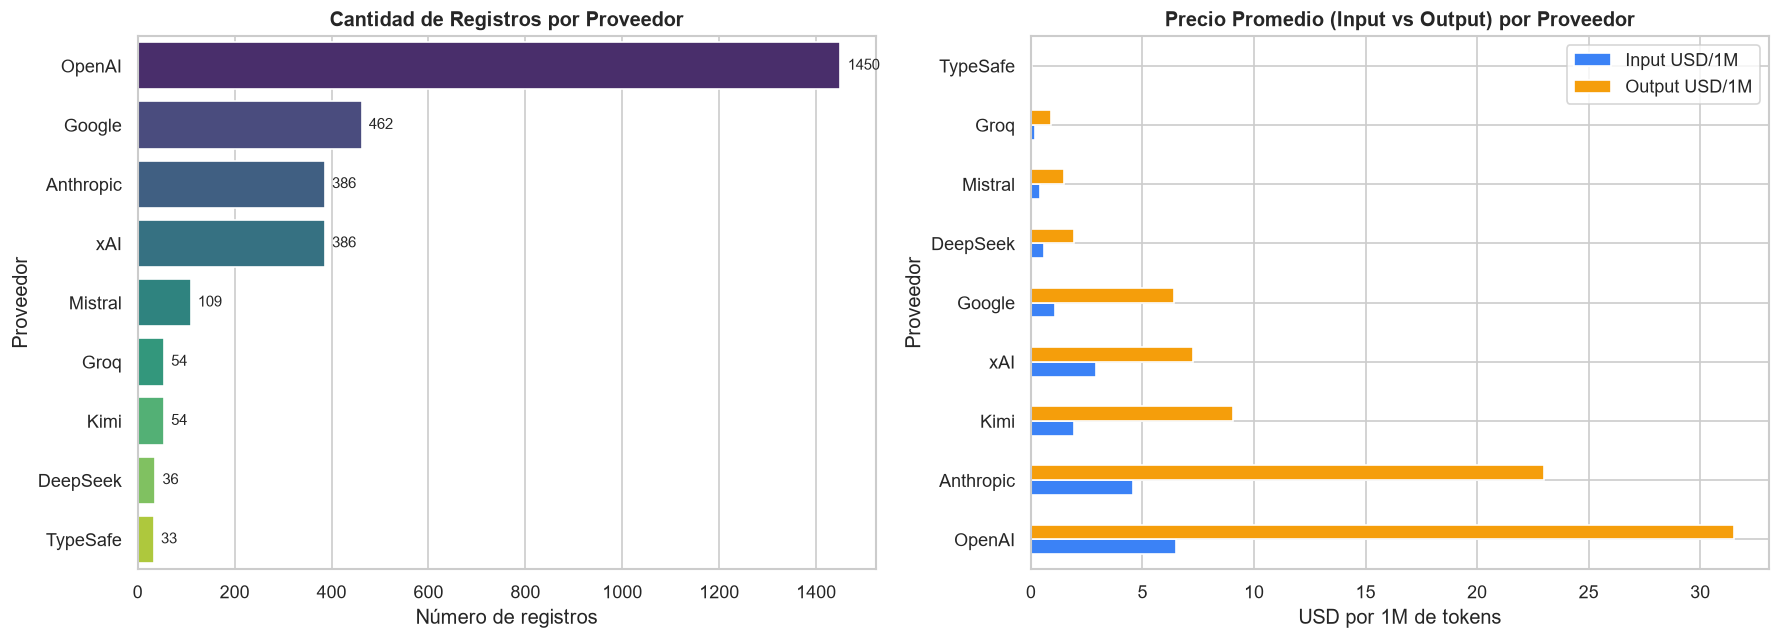

Gráfica guardada en: ..\img\02_precios_por_proveedor.png


In [6]:
# Gráfica Exploratoria 2: Cantidad de registros y precio promedio de entrada/salida por proveedor
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subgráfica A: Conteo de registros por proveedor
conteo_prov = df["provider"].value_counts()
sns.barplot(x=conteo_prov.values, y=conteo_prov.index, ax=axes[0], palette="viridis")
axes[0].set_title("Cantidad de Registros por Proveedor", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Proveedor")
for i, v in enumerate(conteo_prov.values):
    axes[0].text(v + 15, i, str(v), va="center", fontsize=9)

# Subgráfica B: Precio promedio de entrada y salida por proveedor
prom_prov = (
    df.groupby("provider")[["input_usd_per_1m", "output_usd_per_1m"]]
    .mean()
    .sort_values("output_usd_per_1m", ascending=False)
)
prom_prov.plot(kind="barh", ax=axes[1], color=["#3B82F6", "#F59E0B"])
axes[1].set_title("Precio Promedio (Input vs Output) por Proveedor", fontsize=12, fontweight="bold")
axes[1].set_xlabel("USD por 1M de tokens")
axes[1].set_ylabel("Proveedor")
axes[1].legend(["Input USD/1M", "Output USD/1M"])

plt.tight_layout()
ruta_img2 = os.path.join(IMG_DIR, "02_precios_por_proveedor.png")
plt.savefig(ruta_img2, dpi=150, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada en: {ruta_img2}")


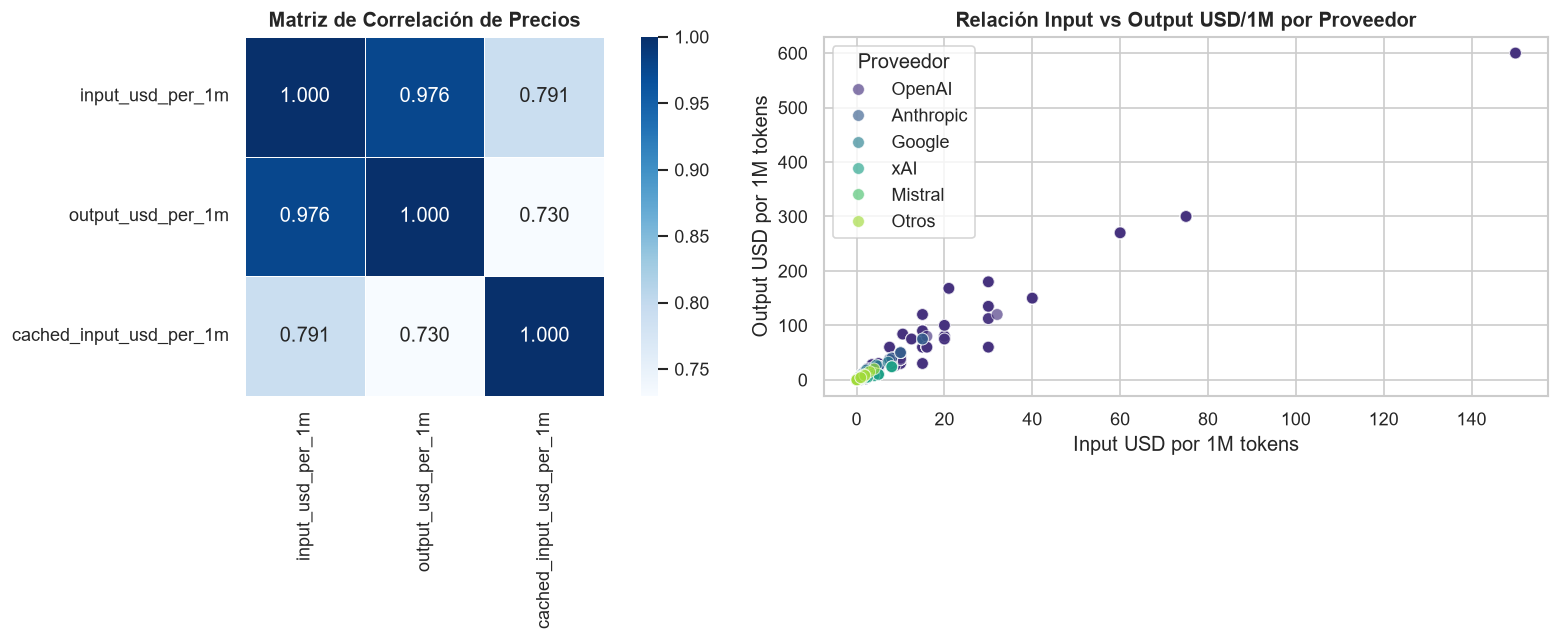

Gráfica guardada en: ..\img\03_correlacion_y_dispersion.png


In [7]:
# Gráfica Exploratoria 3: Mapa de calor de correlaciones y diagrama de dispersión Input vs Output
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subgráfica A: Matriz de correlación entre las 3 variables numéricas de interés
corr = df[cols_precio].corr()
sns.heatmap(corr, annot=True, fmt=".3f", cmap="Blues", square=True, ax=axes[0], linewidths=0.5)
axes[0].set_title("Matriz de Correlación de Precios", fontsize=12, fontweight="bold")

# Subgráfica B: Dispersión Input vs Output coloreada por proveedor (top 5 proveedores)
top_provs = df["provider"].value_counts().head(5).index
df_plot = df.copy()
df_plot["provider_top"] = df_plot["provider"].where(df_plot["provider"].isin(top_provs), "Otros")
sns.scatterplot(
    data=df_plot,
    x="input_usd_per_1m",
    y="output_usd_per_1m",
    hue="provider_top",
    alpha=0.65,
    s=50,
    ax=axes[1]
)
axes[1].set_title("Relación Input vs Output USD/1M por Proveedor", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Input USD por 1M tokens")
axes[1].set_ylabel("Output USD por 1M tokens")
axes[1].legend(title="Proveedor", loc="upper left")

plt.tight_layout()
ruta_img3 = os.path.join(IMG_DIR, "03_correlacion_y_dispersion.png")
plt.savefig(ruta_img3, dpi=150, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada en: {ruta_img3}")


## 2. Limpieza y Preparación de Datos

En esta sección se seleccionan las 3 variables numéricas clave (`input_usd_per_1m`, `output_usd_per_1m`, `cached_input_usd_per_1m`), se eliminan registros con valores nulos en dichas columnas y posibles duplicados, se detectan y eliminan valores atípicos (**outliers**) mediante el método **IQR (1.5 × Rango Intercuartílico)**, y finalmente se estandarizan las variables con `StandardScaler`.


In [8]:
# Selección de las 3 variables numéricas principales y eliminación de nulos y duplicados
features = ["input_usd_per_1m", "output_usd_per_1m", "cached_input_usd_per_1m"]

registros_iniciales = len(df)
print(f"Registros originales: {registros_iniciales}")
print("Nulos en las 3 variables clave antes de limpiar:")
print(df[features].isnull().sum())

# Eliminar filas con nulos en cualquiera de las 3 columnas seleccionadas
df_sin_nulos = df.dropna(subset=features).copy()
eliminados_nulos = registros_iniciales - len(df_sin_nulos)
print(f"\nRegistros eliminados por nulos en las 3 variables: {eliminados_nulos}")

# Eliminar filas completamente duplicadas si existen
antes_dup = len(df_sin_nulos)
df_sin_nulos = df_sin_nulos.drop_duplicates().copy()
eliminados_dup = antes_dup - len(df_sin_nulos)
print(f"Registros duplicados eliminados: {eliminados_dup}")
print(f"Registros disponibles antes del tratamiento de outliers: {len(df_sin_nulos)}")


Registros originales: 2970
Nulos en las 3 variables clave antes de limpiar:
input_usd_per_1m             0
output_usd_per_1m           68
cached_input_usd_per_1m    514
dtype: int64

Registros eliminados por nulos en las 3 variables: 528
Registros duplicados eliminados: 0
Registros disponibles antes del tratamiento de outliers: 2442


In [9]:
# Detección y eliminación de outliers mediante el método IQR (1.5 * IQR)
# Justificación: K-Means minimiza distancias euclidianas al cuadrado; precios extremos
# (modelos 'pro' o ultra-premium de hasta $40 input / $150 output) distorsionan fuertemente
# la posición de los centroides y colapsan el resto del mercado en un solo clúster.

mask_iqr = pd.Series(True, index=df_sin_nulos.index)
limites_iqr = []

for col in features:
    Q1 = df_sin_nulos[col].quantile(0.25)
    Q3 = df_sin_nulos[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    outliers_col = ((df_sin_nulos[col] < lim_inf) | (df_sin_nulos[col] > lim_sup)).sum()
    limites_iqr.append({
        "Variable": col,
        "Q1": round(Q1, 4),
        "Q3": round(Q3, 4),
        "IQR": round(IQR, 4),
        "Límite Superior (Q3+1.5*IQR)": round(lim_sup, 4),
        "Outliers detectados": outliers_col
    })
    mask_iqr &= (df_sin_nulos[col] >= lim_inf) & (df_sin_nulos[col] <= lim_sup)

display(pd.DataFrame(limites_iqr))

df_limpio = df_sin_nulos[mask_iqr].reset_index(drop=True).copy()
eliminados_outliers = len(df_sin_nulos) - len(df_limpio)
pct_outliers = eliminados_outliers / len(df_sin_nulos) * 100

print(f"\nTotal de registros eliminados por outliers (IQR 1.5x): {eliminados_outliers} ({pct_outliers:.2f}%)")
print(f"Total de registros limpios finales para K-Means: {len(df_limpio)}")
print("\nEstadísticas descriptivas después de eliminar outliers:")
display(df_limpio[features].describe().T)


,Variable,Q1,Q3,IQR,Límite Superior (Q3+1.5*IQR),Outliers detectados
0,input_usd_per_1m,0.625,4.0,3.375,9.0625,175
1,output_usd_per_1m,2.500,15.0,12.500,33.7500,213
2,cached_input_usd_per_1m,0.050,0.4,0.350,0.9250,232



Total de registros eliminados por outliers (IQR 1.5x): 291 (11.92%)
Total de registros limpios finales para K-Means: 2151

Estadísticas descriptivas después de eliminar outliers:


,count,mean,std,min,25%,50%,75%,max
input_usd_per_1m,2151.0,1.869121,1.707266,0.0250,0.45,1.32,2.50,8.000
output_usd_per_1m,2151.0,8.444816,8.025008,0.1000,2.00,5.00,12.00,32.400
cached_input_usd_per_1m,2151.0,0.217773,0.206083,0.0025,0.05,0.16,0.36,0.875


In [10]:
# Escalamiento de las 3 variables numéricas usando StandardScaler (media=0, desviación estándar=1)
scaler = StandardScaler()
X_raw = df_limpio[features].values
X_scaled = scaler.fit_transform(X_raw)

# Verificación rápida del escalamiento
df_scaled_check = pd.DataFrame(X_scaled, columns=features)
print("Verificación de media (~0) y desviación estándar (~1) tras StandardScaler:")
display(df_scaled_check.describe().loc[["mean", "std", "min", "max"]].round(4))


Verificación de media (~0) y desviación estándar (~1) tras StandardScaler:


,input_usd_per_1m,output_usd_per_1m,cached_input_usd_per_1m
mean,-0.0000,-0.0000,0.0000
std,1.0002,1.0002,1.0002
min,-1.0804,-1.0401,-1.0448
max,3.5919,2.9858,3.1899


## 3. Implementación de K-Means (Evaluación de K = 2, 3, 4, 5, 6)

Evaluamos 5 valores candidatos de $K \in \{2, 3, 4, 5, 6\}$ con `random_state=42` y `n_init=10`, calculando la **Inercia** (Método del Codo) y el **Silhouette Score** para seleccionar el número óptimo de clústeres.


Tabla de evaluación para K = 2, 3, 4, 5, 6:


,K,Inercia,Silhouette_Score,Iteraciones
0,2,2456.54,0.6012,3
1,3,1491.37,0.5086,6
2,4,1106.62,0.5310,8
3,5,848.59,0.5192,5
4,6,635.61,0.5205,5


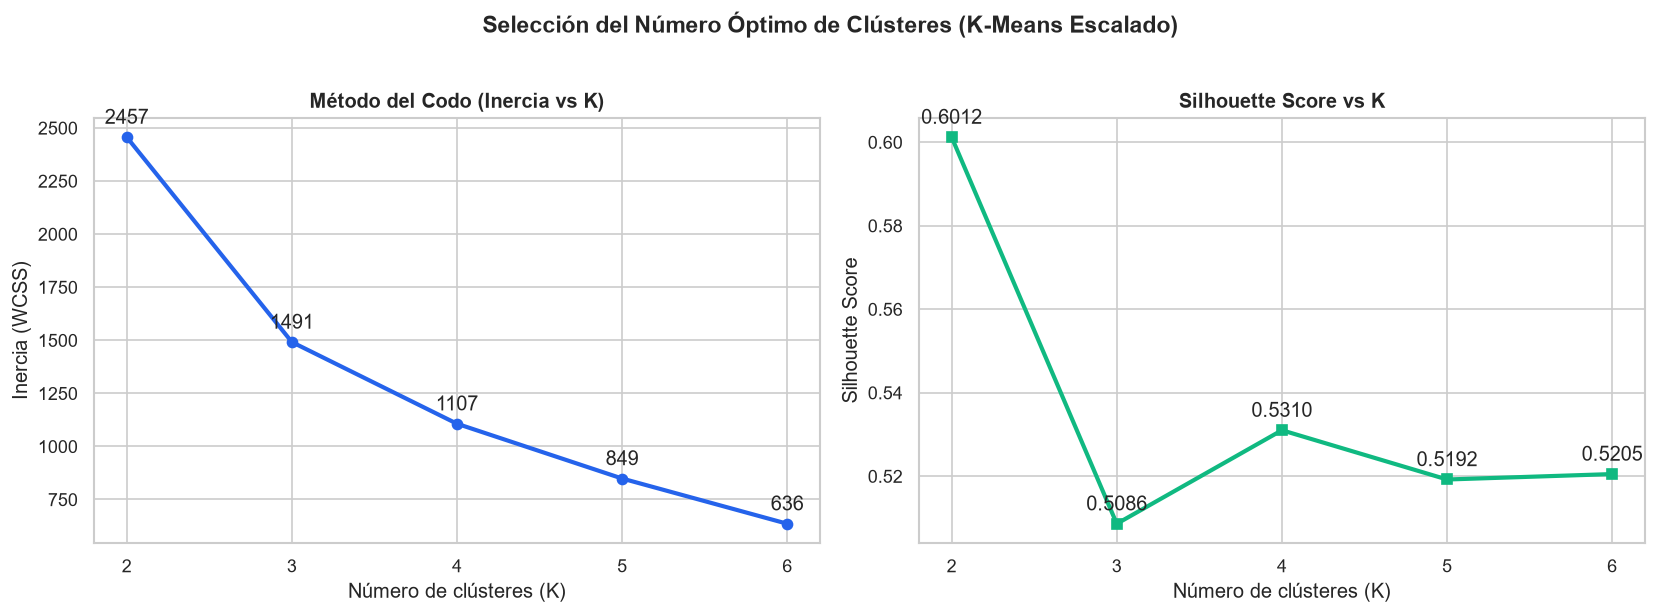

Gráfica guardada en: ..\img\04_codo_y_silhouette.png


In [11]:
# Evaluación sistemática de K = 2, 3, 4, 5, 6 con datos escalados
k_values = [2, 3, 4, 5, 6]
resultados_k = []

for k in k_values:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    inercia = modelo.inertia_
    sil = silhouette_score(X_scaled, etiquetas)
    resultados_k.append({
        "K": k,
        "Inercia": round(inercia, 2),
        "Silhouette_Score": round(sil, 4),
        "Iteraciones": modelo.n_iter_
    })

df_metricas_k = pd.DataFrame(resultados_k)
print("Tabla de evaluación para K = 2, 3, 4, 5, 6:")
display(df_metricas_k)

# Gráfica dual: Método del Codo (Inercia) y Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(df_metricas_k["K"], df_metricas_k["Inercia"], marker="o", linewidth=2.5, color="#2563EB")
axes[0].set_title("Método del Codo (Inercia vs K)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Número de clústeres (K)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_xticks(k_values)
for _, row in df_metricas_k.iterrows():
    axes[0].annotate(f"{row['Inercia']:.0f}", (row["K"], row["Inercia"]), textcoords="offset points", xytext=(0, 8), ha="center")

axes[1].plot(df_metricas_k["K"], df_metricas_k["Silhouette_Score"], marker="s", linewidth=2.5, color="#10B981")
axes[1].set_title("Silhouette Score vs K", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Número de clústeres (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_values)
for _, row in df_metricas_k.iterrows():
    axes[1].annotate(f"{row['Silhouette_Score']:.4f}", (row["K"], row["Silhouette_Score"]), textcoords="offset points", xytext=(0, 8), ha="center")

plt.suptitle("Selección del Número Óptimo de Clústeres (K-Means Escalado)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_img4 = os.path.join(IMG_DIR, "04_codo_y_silhouette.png")
plt.savefig(ruta_img4, dpi=150, bbox_inches="tight")
plt.show()
print(f"Gráfica guardada en: {ruta_img4}")


In [12]:
# Entrenamiento del modelo final con K=4 (mejor equilibrio entre codo, mayor Silhouette para K>=3 y riqueza de negocio)
# Nota: K=2 solo divide en 'barato' vs 'caro'. Entre K=3..6, K=4 logra el mayor Silhouette Score (0.5310)
# y separa claramente un segmento especializado de 'Contexto Largo / Caché Alto'.

K_OPTIMO = 4
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
df_limpio["Cluster"] = kmeans_final.fit_predict(X_scaled)

sil_final = silhouette_score(X_scaled, df_limpio["Cluster"])

print(f"Modelo final entrenado con K = {K_OPTIMO}")
print(f"Número de iteraciones hasta convergencia (n_iter_): {kmeans_final.n_iter_}")
print(f"Inercia final: {kmeans_final.inertia_:.2f}")
print(f"Silhouette Score final: {sil_final:.4f}\n")

# Cantidad de registros por clúster
conteo_clusters = df_limpio["Cluster"].value_counts().sort_index()
pct_clusters = (conteo_clusters / len(df_limpio) * 100).round(2)
print("Distribución de registros por clúster:")
display(pd.DataFrame({"Registros": conteo_clusters, "Porcentaje (%)": pct_clusters}))

# Centroides desescalados a dólares reales usando scaler.inverse_transform()
centroides_reales = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=features
)
centroides_reales.index.name = "Cluster"
centroides_reales["Registros"] = conteo_clusters.values
print("\nCentroides desescalados (en USD reales por 1M de tokens):")
display(centroides_reales.round(4))


Modelo final entrenado con K = 4
Número de iteraciones hasta convergencia (n_iter_): 8
Inercia final: 1106.62
Silhouette Score final: 0.5310

Distribución de registros por clúster:


,Registros,Porcentaje (%)
Cluster,,
0,1051,48.86
1,326,15.16
2,683,31.75
3,91,4.23



Centroides desescalados (en USD reales por 1M de tokens):


,input_usd_per_1m,output_usd_per_1m,cached_input_usd_per_1m,Registros
Cluster,,,,
0,0.5462,2.6426,0.0660,1051
1,4.9255,24.0537,0.4455,326
2,2.1343,9.5899,0.2684,683
3,4.2088,10.9451,0.7753,91


## 4. Comparación de 2 Configuraciones (Datos Escalados vs. Datos Sin Escalar)

Comparamos nuestro **Modelo Final (K=4 con `StandardScaler`)** contra una **segunda configuración (K=4 sin escalar)** para evaluar cómo la diferencia de escalas entre `output_usd_per_1m` (hasta \$33.75) y `cached_input_usd_per_1m` (hasta \$0.90) afecta el Silhouette Score, la distribución de los grupos y la formación de centroides.


Tabla comparativa entre las 2 configuraciones:


,Configuración,Silhouette (Espacio Estandarizado),Silhouette (Espacio Original USD),Iteraciones,Distribución de Clústeres
0,"1. Modelo Final (K=4, Escalado con StandardSca...",0.5310,0.3626,8,"{0: np.int64(1051), 1: np.int64(326), 2: np.in..."
1,"2. Sin Escalar (K=4, Valores Originales USD)",0.3627,0.5736,5,"{0: np.int64(494), 1: np.int64(242), 2: np.int..."



Centroides de la Configuración 2 (Sin Escalar, en USD):


,input_usd_per_1m,output_usd_per_1m,cached_input_usd_per_1m,Registros
Cluster_Sin_Escalar,,,,
0,2.0126,8.5582,0.2765,494
1,5.2467,26.1467,0.4802,242
2,0.7170,2.5738,0.1034,1111
3,3.1577,15.6253,0.3315,304


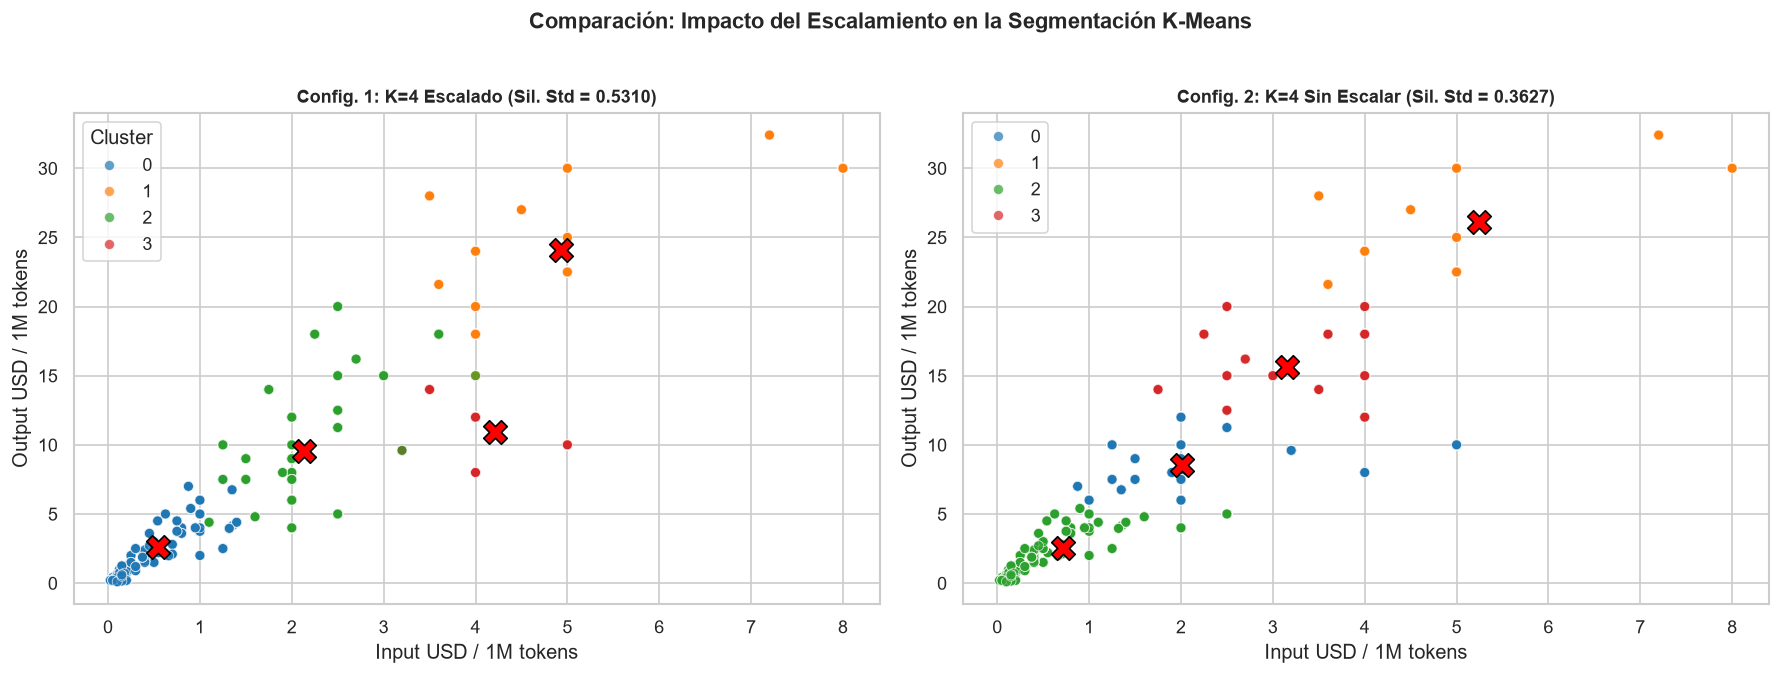


Conclusión de la comparación:
- Sin escalar, output_usd_per_1m domina la distancia euclidiana e ignora el costo de caché (cached_input_usd_per_1m).
- Con StandardScaler, las 3 dimensiones contribuyen por igual, elevando la cohesión multivariada (Silhouette Std: 0.5310)
  y revelando el segmento diferenciado de Contexto Largo / Caché Alto.


In [13]:
# Entrenamiento de la Configuración 2: K=4 con datos SIN escalar (en dólares originales)
kmeans_sin_escalar = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
labels_sin_escalar = kmeans_sin_escalar.fit_predict(X_raw)

# Cálculo de Silhouette Score para ambas configuraciones
# Evaluamos también el modelo sin escalar en el espacio estandarizado para una comparación justa multivariada
sil_escalado = silhouette_score(X_scaled, df_limpio["Cluster"])
sil_sin_escalar_raw = silhouette_score(X_raw, labels_sin_escalar)
sil_sin_escalar_en_std = silhouette_score(X_scaled, labels_sin_escalar)

comparacion_metricas = pd.DataFrame([
    {
        "Configuración": "1. Modelo Final (K=4, Escalado con StandardScaler)",
        "Silhouette (Espacio Estandarizado)": round(sil_escalado, 4),
        "Silhouette (Espacio Original USD)": round(silhouette_score(X_raw, df_limpio["Cluster"]), 4),
        "Iteraciones": kmeans_final.n_iter_,
        "Distribución de Clústeres": str(dict(pd.Series(df_limpio["Cluster"]).value_counts().sort_index()))
    },
    {
        "Configuración": "2. Sin Escalar (K=4, Valores Originales USD)",
        "Silhouette (Espacio Estandarizado)": round(sil_sin_escalar_en_std, 4),
        "Silhouette (Espacio Original USD)": round(sil_sin_escalar_raw, 4),
        "Iteraciones": kmeans_sin_escalar.n_iter_,
        "Distribución de Clústeres": str(dict(pd.Series(labels_sin_escalar).value_counts().sort_index()))
    }
])

print("Tabla comparativa entre las 2 configuraciones:")
display(comparacion_metricas)

centroides_sin_escalar = pd.DataFrame(kmeans_sin_escalar.cluster_centers_, columns=features)
centroides_sin_escalar.index.name = "Cluster_Sin_Escalar"
centroides_sin_escalar["Registros"] = pd.Series(labels_sin_escalar).value_counts().sort_index().values
print("\nCentroides de la Configuración 2 (Sin Escalar, en USD):")
display(centroides_sin_escalar.round(4))

# Comparación visual lado a lado de ambas configuraciones
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(
    x=df_limpio["input_usd_per_1m"],
    y=df_limpio["output_usd_per_1m"],
    hue=df_limpio["Cluster"],
    palette="tab10",
    alpha=0.7,
    ax=axes[0]
)
axes[0].scatter(
    centroides_reales["input_usd_per_1m"],
    centroides_reales["output_usd_per_1m"],
    marker="X", s=200, color="red", edgecolor="black", linewidth=1, label="Centroides"
)
axes[0].set_title(f"Config. 1: K=4 Escalado (Sil. Std = {sil_escalado:.4f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Input USD / 1M tokens")
axes[0].set_ylabel("Output USD / 1M tokens")

sns.scatterplot(
    x=df_limpio["input_usd_per_1m"],
    y=df_limpio["output_usd_per_1m"],
    hue=labels_sin_escalar,
    palette="tab10",
    alpha=0.7,
    ax=axes[1]
)
axes[1].scatter(
    centroides_sin_escalar["input_usd_per_1m"],
    centroides_sin_escalar["output_usd_per_1m"],
    marker="X", s=200, color="red", edgecolor="black", linewidth=1, label="Centroides"
)
axes[1].set_title(f"Config. 2: K=4 Sin Escalar (Sil. Std = {sil_sin_escalar_en_std:.4f})", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Input USD / 1M tokens")
axes[1].set_ylabel("Output USD / 1M tokens")

plt.suptitle("Comparación: Impacto del Escalamiento en la Segmentación K-Means", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("\nConclusión de la comparación:")
print("- Sin escalar, output_usd_per_1m domina la distancia euclidiana e ignora el costo de caché (cached_input_usd_per_1m).")
print("- Con StandardScaler, las 3 dimensiones contribuyen por igual, elevando la cohesión multivariada (Silhouette Std: 0.5310)")
print("  y revelando el segmento diferenciado de Contexto Largo / Caché Alto.")


## 5. Interpretación de Clústeres y Exportación de Resultados

Asignamos nombres descriptivos de negocio a cada clúster con base en sus centroides desescalados en dólares reales, mostramos las estadísticas comparativas, graficamos el scatter plot final con centroides marcados con **X roja** y exportamos el dataset procesado a `data/dataset_procesado.csv`.


In [14]:
# Asignación dinámica y determinista de nombres descriptivos ordenando por características reales de los centroides
# Verificamos qué clúster corresponde a cada perfil según sus centroides desescalados:
# - Menor input/output promedio -> Modelos Económicos / Batch
# - Mayor output promedio       -> Modelos Premium / Alto Rendimiento
# - Mayor cached_input promedio -> Contexto Largo / Caché Alto
# - Restante (intermedio)       -> Gama Media Estándar

c_df = centroides_reales.copy()
id_economico = c_df["output_usd_per_1m"].idxmin()
id_premium = c_df["output_usd_per_1m"].idxmax()
id_cache_alto = c_df["cached_input_usd_per_1m"].idxmax()
id_media = [c for c in c_df.index if c not in {id_economico, id_premium, id_cache_alto}][0]

mapa_nombres = {
    id_economico: "Modelos Económicos / Batch",
    id_media: "Gama Media Estándar",
    id_cache_alto: "Contexto Largo / Caché Alto",
    id_premium: "Modelos Premium / Alto Rendimiento"
}

df_limpio["Nombre_Cluster"] = df_limpio["Cluster"].map(mapa_nombres)
centroides_reales["Nombre_Cluster"] = centroides_reales.index.map(mapa_nombres)

print("Mapa de nombres descriptivos asignados:")
for k_id, nombre in sorted(mapa_nombres.items()):
    print(f"  Clúster {k_id} -> {nombre}")

# Tabla comparativa con estadísticas descriptivas por grupo
tabla_comparativa = df_limpio.groupby("Nombre_Cluster")[features].agg(["count", "mean", "median", "std", "min", "max"]).round(4)
print("\nTabla comparativa de estadísticas descriptivas por clúster:")
display(tabla_comparativa)


Mapa de nombres descriptivos asignados:
  Clúster 0 -> Modelos Económicos / Batch
  Clúster 1 -> Modelos Premium / Alto Rendimiento
  Clúster 2 -> Gama Media Estándar
  Clúster 3 -> Contexto Largo / Caché Alto

Tabla comparativa de estadísticas descriptivas por clúster:


input_usd_per_1m                         \
                                              count    mean median     std   
Nombre_Cluster                                                               
Contexto Largo / Caché Alto                      91  4.2088    4.0  0.6907   
Gama Media Estándar                             683  2.1343    2.0  0.5445   
Modelos Económicos / Batch                     1051  0.5462    0.4  0.4030   
Modelos Premium / Alto Rendimiento              326  4.9255    5.0  1.1370   

                                               output_usd_per_1m           \
                                      min  max             count     mean   
Nombre_Cluster                                                              
Contexto Largo / Caché Alto         3.200  5.0                91  10.9451   
Gama Media Estándar                 1.100  4.0               683   9.5899   
Modelos Económicos / Batch          0.025  1.4              1051   2.6426   
Modelos Premium / Alto Rendimiento  3.500  8.0               326  24.0537   

                                                               \
                                   median     std   min   max   
Nombre_Cluster                                                  
Contexto Largo / Caché Alto          10.0  1.8748   8.0  14.0   
Gama Media Estándar                   9.0  4.0563   4.0  20.0   
Modelos Económicos / Batch            2.0  2.0026   0.1   7.5   
Modelos Premium / Alto Rendimiento   25.0  4.4517  15.0  32.4   

                                   cached_input_usd_per_1m                 \
                                                     count    mean median   
Nombre_Cluster                                                              
Contexto Largo / Caché Alto                             91  0.7753   0.80   
Gama Media Estándar                                    683  0.2684   0.25   
Modelos Económicos / Batch                            1051  0.0660   0.05   
Modelos Premium / Alto Rendimiento                     326  0.4455   0.50   

                                                           
                                       std     min    max  
Nombre_Cluster                                             
Contexto Largo / Caché Alto         0.0922  0.6000  0.875  
Gama Media Estándar                 0.1141  0.1000  0.550  
Modelos Económicos / Batch          0.0594  0.0025  0.250  
Modelos Premium / Alto Rendimiento  0.1449  0.1250  0.800

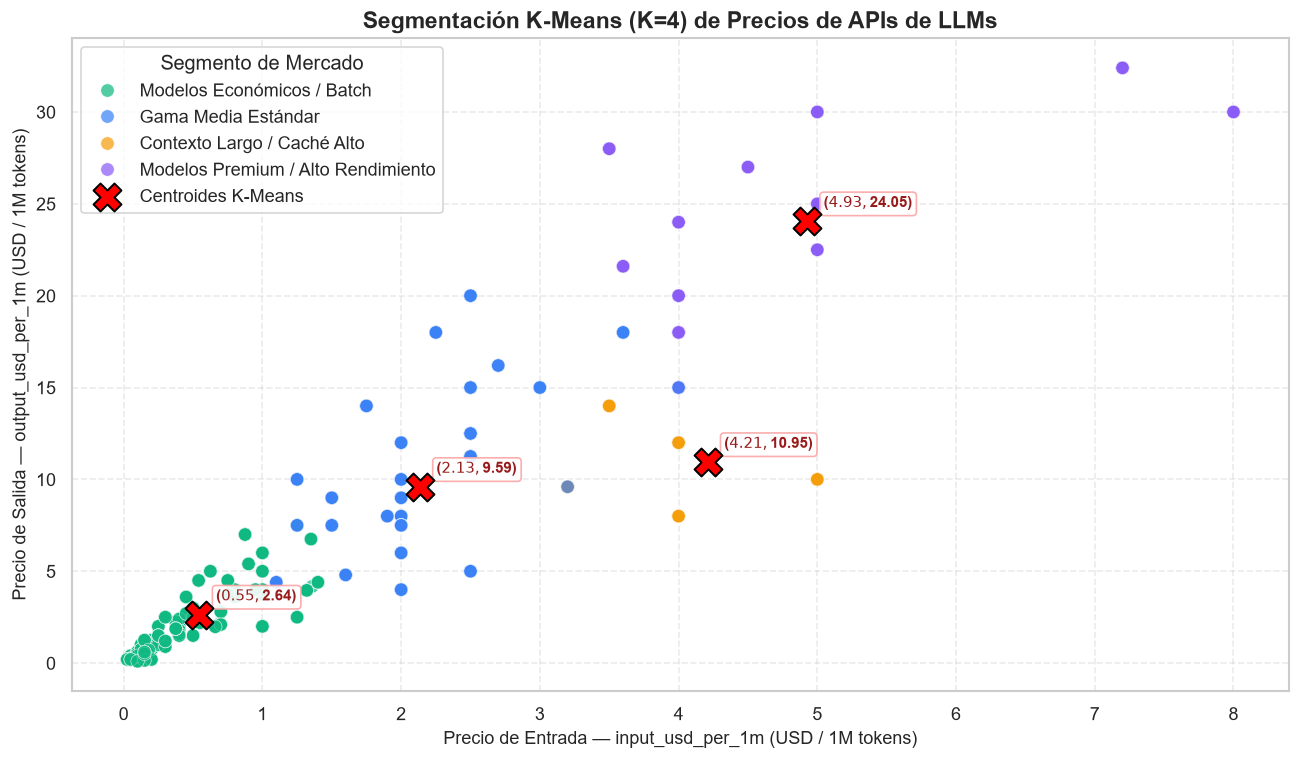

Gráfica final de clústeres guardada en: ..\img\05_clusters_kmeans.png


In [15]:
# Gráfica final de clústeres: Scatter plot (Input vs Output) con centroides marcados con X roja
orden_clusters = [
    "Modelos Económicos / Batch",
    "Gama Media Estándar",
    "Contexto Largo / Caché Alto",
    "Modelos Premium / Alto Rendimiento"
]
paleta_clusters = {
    "Modelos Económicos / Batch": "#10B981",
    "Gama Media Estándar": "#3B82F6",
    "Contexto Largo / Caché Alto": "#F59E0B",
    "Modelos Premium / Alto Rendimiento": "#8B5CF6"
}

plt.figure(figsize=(11, 6.5))
sns.scatterplot(
    data=df_limpio,
    x="input_usd_per_1m",
    y="output_usd_per_1m",
    hue="Nombre_Cluster",
    hue_order=orden_clusters,
    palette=paleta_clusters,
    alpha=0.72,
    s=65,
    edgecolor="white",
    linewidth=0.4
)

# Marcar centroides desescalados con X roja
plt.scatter(
    centroides_reales["input_usd_per_1m"],
    centroides_reales["output_usd_per_1m"],
    marker="X",
    s=280,
    color="red",
    edgecolor="black",
    linewidth=1.2,
    zorder=10,
    label="Centroides K-Means"
)

# Etiquetar cada centroide con su precio real
for _, row in centroides_reales.iterrows():
    plt.annotate(
        f"(${row['input_usd_per_1m']:.2f}, ${row['output_usd_per_1m']:.2f})",
        (row["input_usd_per_1m"], row["output_usd_per_1m"]),
        textcoords="offset points",
        xytext=(10, 8),
        fontsize=9,
        fontweight="bold",
        color="#991B1B",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#FCA5A5", alpha=0.9)
    )

plt.title("Segmentación K-Means (K=4) de Precios de APIs de LLMs", fontsize=14, fontweight="bold")
plt.xlabel("Precio de Entrada — input_usd_per_1m (USD / 1M tokens)", fontsize=11)
plt.ylabel("Precio de Salida — output_usd_per_1m (USD / 1M tokens)", fontsize=11)
plt.legend(title="Segmento de Mercado", loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

ruta_img5 = os.path.join(IMG_DIR, "05_clusters_kmeans.png")
plt.savefig(ruta_img5, dpi=150, bbox_inches="tight")
plt.show()
print(f"Gráfica final de clústeres guardada en: {ruta_img5}")


In [16]:
# Exportación del dataset procesado con las columnas Cluster y Nombre_Cluster
ruta_salida = os.path.join(DATA_DIR, "dataset_procesado.csv")
df_limpio.to_csv(ruta_salida, index=False, encoding="utf-8")

print(f"Dataset procesado exportado exitosamente en: {ruta_salida}")
print(f"Dimensiones exportadas: {df_limpio.shape[0]} filas x {df_limpio.shape[1]} columnas")
print("Primeros 5 registros de las columnas clave exportadas:")
display(df_limpio[["provider", "model_id", "price_tier", "input_usd_per_1m", "output_usd_per_1m", "cached_input_usd_per_1m", "Cluster", "Nombre_Cluster"]].head())


Dataset procesado exportado exitosamente en: ..\data\dataset_procesado.csv
Dimensiones exportadas: 2151 filas x 24 columnas
Primeros 5 registros de las columnas clave exportadas:


,provider,model_id,price_tier,input_usd_per_1m,output_usd_per_1m,cached_input_usd_per_1m,Cluster,Nombre_Cluster
0,OpenAI,gpt-5.6-sol,standard,4.0,20.0,0.40,1,Modelos Premium / Alto Rendimiento
1,OpenAI,gpt-5.6-sol,standard_long_context,8.0,30.0,0.80,1,Modelos Premium / Alto Rendimiento
2,OpenAI,gpt-5.6-terra,standard,2.0,12.0,0.20,2,Gama Media Estándar
3,OpenAI,gpt-5.6-terra,standard_long_context,4.0,18.0,0.40,1,Modelos Premium / Alto Rendimiento
4,OpenAI,gpt-5.6-luna,standard,0.2,1.2,0.02,0,Modelos Económicos / Batch
